In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the dataset from your computer
uploaded = files.upload()


Saving student-mat.csv to student-mat.csv
Saving student-por.csv to student-por.csv


In [2]:

# Read the uploaded dataset
df = pd.read_csv("student-por.csv", sep=";")

# Display the first five records
display(df.head())

# Check the dataset size
print("Dataset Shape:", df.shape)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Dataset Shape: (649, 33)


In [3]:

# Display dataset information
print("DATASET INFORMATION")
print("-" * 40)

df.info()

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display basic statistics
print("\nDATASET STATISTICS")
display(df.describe())


DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [4]:

# Check missing values
print("MISSING VALUES")
print("-" * 40)
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# Check total missing values
print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())


MISSING VALUES
----------------------------------------
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

DUPLICATE RECORDS
0

TOTAL MISSING VALUES
0


In [5]:

# Create target variable using final grade (G3)
df["Student_Risk"] = (df["G3"] < 10).astype(int)

# Display sample results
print("STUDENT RISK CLASSIFICATION")
print("-" * 40)

display(df[["G3", "Student_Risk"]].head(10))

# Count students in each category
print("\nSTUDENT RISK DISTRIBUTION")
print(df["Student_Risk"].value_counts())

# Show percentages
print("\nSTUDENT RISK PERCENTAGES")
print(df["Student_Risk"].value_counts(normalize=True) * 100)


STUDENT RISK CLASSIFICATION
----------------------------------------


,G3,Student_Risk
0,11,0
1,11,0
2,12,0
3,14,0
4,13,0
5,13,0
6,13,0
7,13,0
8,17,0
9,13,0



STUDENT RISK DISTRIBUTION
Student_Risk
0    549
1    100
Name: count, dtype: int64

STUDENT RISK PERCENTAGES
Student_Risk
0    84.59168
1    15.40832
Name: proportion, dtype: float64


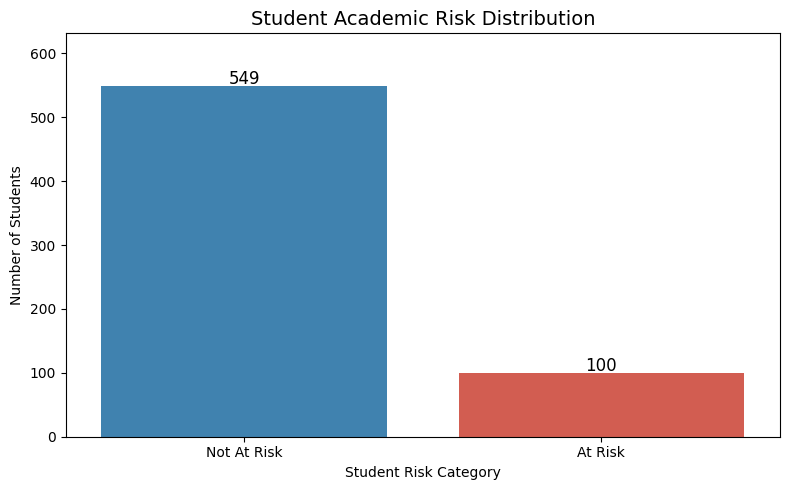

STUDENT RISK DISTRIBUTION
Not At Risk: 549 students (84.59%)
At Risk: 100 students (15.41%)


In [6]:

# Cell 6: Student Risk Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Count students in each category
risk_counts = df["Student_Risk"].value_counts().reindex(
    [0, 1], fill_value=0
)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Not At Risk", "At Risk"],
    y=risk_counts.values,
    hue=["Not At Risk", "At Risk"],
    palette=["#2E86C1", "#E74C3C"],
    legend=False
)

# Add count labels
for i, count in enumerate(risk_counts.values):
    plt.text(i, count + 3, str(count),
             ha="center", fontsize=12)

plt.title("Student Academic Risk Distribution", fontsize=14)
plt.xlabel("Student Risk Category")
plt.ylabel("Number of Students")
plt.ylim(0, max(risk_counts.values) * 1.15)
plt.tight_layout()
plt.show()

# Display exact percentages
print("STUDENT RISK DISTRIBUTION")
for category, count in risk_counts.items():
    label = "Not At Risk" if category == 0 else "At Risk"
    percentage = count / len(df) * 100
    print(f"{label}: {count} students ({percentage:.2f}%)")


STUDY TIME AND ACADEMIC RISK


,Study_Time,count,Risk_Percentage
0,< 2 hours,212,23.584906
1,2–5 hours,305,13.442623
2,5–10 hours,97,7.216495
3,> 10 hours,35,5.714286


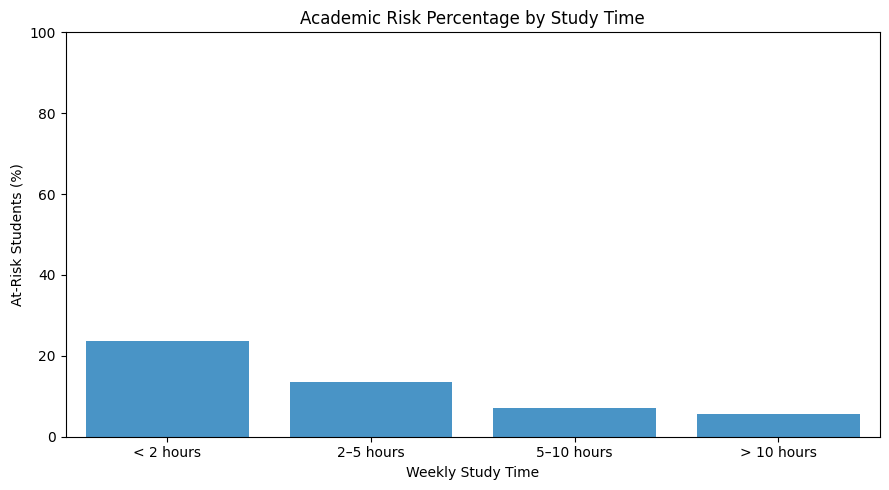

In [7]:

# Cell 7: Study Time vs Student Academic Risk

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Study time categories in the UCI dataset
study_labels = {
    1: "< 2 hours",
    2: "2–5 hours",
    3: "5–10 hours",
    4: "> 10 hours"
}

# Create readable study time labels
df["Study_Time_Category"] = df["studytime"].map(study_labels)

# Calculate percentage of at-risk students
study_risk = (
    df.groupby("studytime")["Student_Risk"]
    .agg(["count", "mean"])
    .reset_index()
)

study_risk["Risk_Percentage"] = study_risk["mean"] * 100
study_risk["Study_Time"] = study_risk["studytime"].map(study_labels)

# Display results
print("STUDY TIME AND ACADEMIC RISK")
display(study_risk[
    ["Study_Time", "count", "Risk_Percentage"]
])

# Create visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=study_risk,
    x="Study_Time",
    y="Risk_Percentage",
    color="#3498DB"
)

plt.title("Academic Risk Percentage by Study Time")
plt.xlabel("Weekly Study Time")
plt.ylabel("At-Risk Students (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


PREVIOUS FAILURES VS ACADEMIC RISK


,Previous_Failures,Total_Students,Risk_Percentage
0,0,549,9.289617
1,1,70,45.714286
2,2,16,50.000000
3,3,14,64.285714


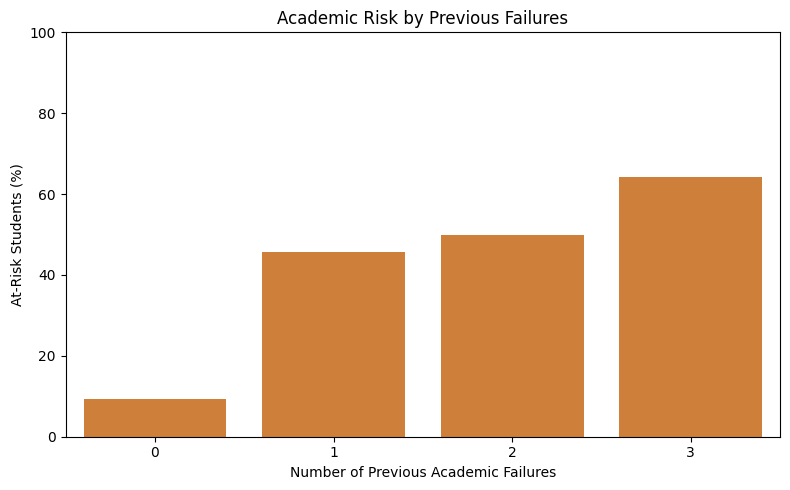

In [8]:

# Cell 8: Previous Academic Failures vs Student Risk

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate student counts and risk percentage
failure_risk = (
    df.groupby("failures")["Student_Risk"]
    .agg(["count", "mean"])
    .reset_index()
)

# Convert risk rate into percentage
failure_risk["Risk_Percentage"] = (
    failure_risk["mean"] * 100
)

# Rename columns for better understanding
failure_risk = failure_risk.rename(
    columns={
        "failures": "Previous_Failures",
        "count": "Total_Students"
    }
)

# Display analysis table
print("PREVIOUS FAILURES VS ACADEMIC RISK")
display(
    failure_risk[
        [
            "Previous_Failures",
            "Total_Students",
            "Risk_Percentage"
        ]
    ]
)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=failure_risk,
    x="Previous_Failures",
    y="Risk_Percentage",
    color="#E67E22"
)

plt.title("Academic Risk by Previous Failures")
plt.xlabel("Number of Previous Academic Failures")
plt.ylabel("At-Risk Students (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [9]:

# Cell 9: Feature Preparation

# Remove grades to avoid data leakage
# Remove the target and EDA-only column
X = df.drop(
    columns=[
        "G1", "G2", "G3",
        "Student_Risk",
        "Study_Time_Category"
    ],
    errors="ignore"
)

# Target variable
y = df["Student_Risk"]

print("Input features:", X.shape)
print("Target:", y.shape)
print("\nClass distribution:")
print(y.value_counts())

print("\nInput columns:")
print(X.columns.tolist())


Input features: (649, 30)
Target: (649,)

Class distribution:
Student_Risk
0    549
1    100
Name: count, dtype: int64

Input columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [10]:

# Cell 10: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 519
Testing samples: 130


In [11]:

# Cell 11: Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Numerical features: 13
Categorical features: 17


In [12]:

# Cell 12: Logistic Regression Model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]


Logistic Regression training completed!


In [13]:

# Cell 13: Random Forest Model

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]


Random Forest training completed!


In [14]:

# Cell 14: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

def evaluate_model(name, y_true, predictions, probabilities):
    print(f"\n{name}")
    print("-" * 45)

    print("Accuracy:",
          round(accuracy_score(y_true, predictions), 4))
    print("Precision:",
          round(precision_score(y_true, predictions,
                                zero_division=0), 4))
    print("Recall:",
          round(recall_score(y_true, predictions,
                             zero_division=0), 4))
    print("F1 Score:",
          round(f1_score(y_true, predictions,
                         zero_division=0), 4))
    print("ROC-AUC:",
          round(roc_auc_score(y_true, probabilities), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["Not At Risk", "At Risk"],
        zero_division=0
    ))

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)



Logistic Regression
---------------------------------------------
Accuracy: 0.7692
Precision: 0.3529
Recall: 0.6
F1 Score: 0.4444
ROC-AUC: 0.7759

Classification Report:
              precision    recall  f1-score   support

 Not At Risk       0.92      0.80      0.85       110
     At Risk       0.35      0.60      0.44        20

    accuracy                           0.77       130
   macro avg       0.63      0.70      0.65       130
weighted avg       0.83      0.77      0.79       130


Random Forest
---------------------------------------------
Accuracy: 0.8385
Precision: 0.3333
Recall: 0.05
F1 Score: 0.087
ROC-AUC: 0.8105

Classification Report:
              precision    recall  f1-score   support

 Not At Risk       0.85      0.98      0.91       110
     At Risk       0.33      0.05      0.09        20

    accuracy                           0.84       130
   macro avg       0.59      0.52      0.50       130
weighted avg       0.77      0.84      0.78       130



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7692,0.3529,0.60,0.4444,0.7759
1,Random Forest,0.8385,0.3333,0.05,0.0870,0.8105


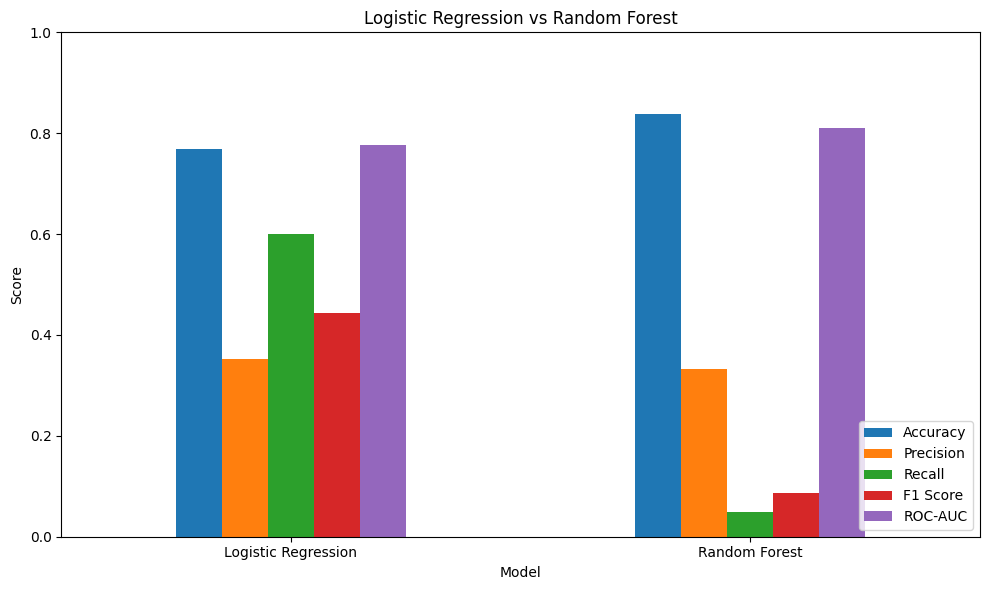

In [15]:

# Cell 15: Model Comparison

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

display(results.round(4))

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


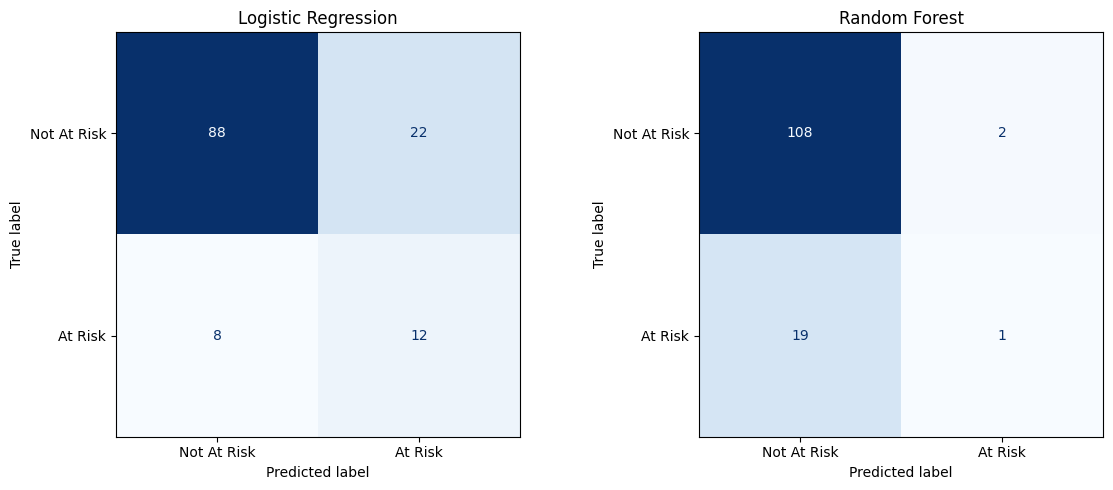

In [16]:

# Cell 16: Confusion Matrices

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in zip(
    axes,
    ["Logistic Regression", "Random Forest"],
    [lr_predictions, rf_predictions]
):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not At Risk", "At Risk"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


TOP 15 IMPORTANT FEATURES


,Feature,Importance
5,num__failures,0.099832
14,cat__school_MS,0.059148
13,cat__school_GP,0.050976
12,num__absences,0.047381
8,num__goout,0.038283
4,num__studytime,0.035153
7,num__freetime,0.034408
10,num__Walc,0.033868
6,num__famrel,0.033043
2,num__Fedu,0.033000


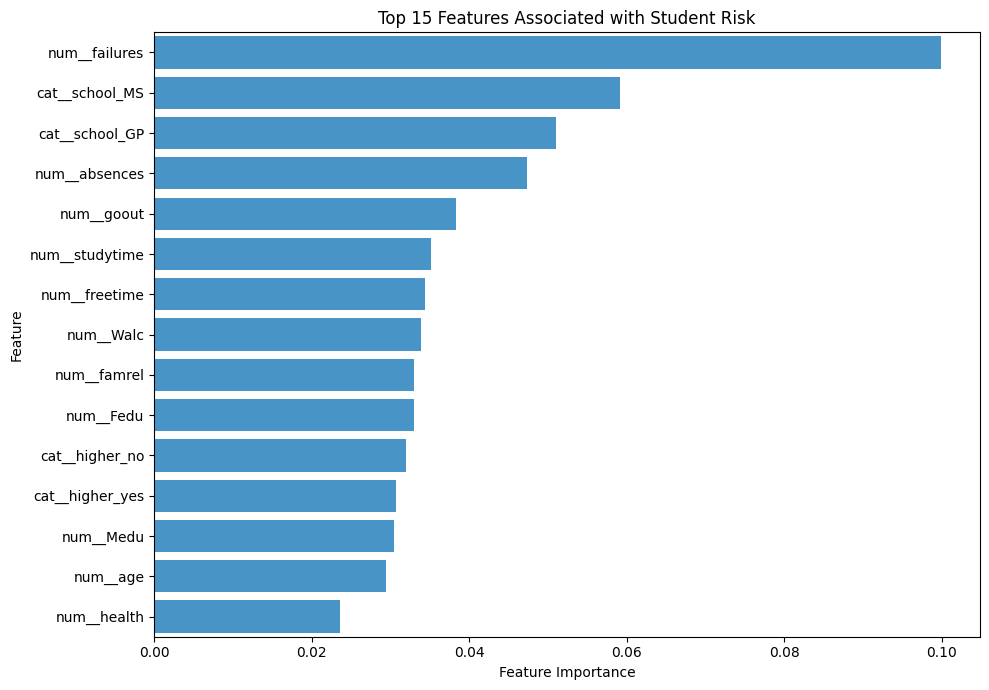

In [17]:

# Cell 17: Random Forest Feature Importance

# Get transformed feature names
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get importance values
importances = rf_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    color="#3498DB"
)

plt.title("Top 15 Features Associated with Student Risk")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [18]:

# Cell 18: Student Risk Predictions

# Select the model with higher at-risk F1 score
best_model_name = results.loc[
    results["F1 Score"].idxmax(), "Model"
]

best_model = (
    lr_model if best_model_name == "Logistic Regression"
    else rf_model
)

print("Selected Model:", best_model_name)

# Predict risk probabilities
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create a results table
prediction_results = pd.DataFrame({
    "Actual_Risk": y_test.values,
    "Predicted_Risk": best_model.predict(X_test),
    "Risk_Probability": test_probabilities
})

prediction_results["Actual_Category"] = (
    prediction_results["Actual_Risk"]
    .map({0: "Not At Risk", 1: "At Risk"})
)

prediction_results["Predicted_Category"] = (
    prediction_results["Predicted_Risk"]
    .map({0: "Not At Risk", 1: "At Risk"})
)

display(prediction_results.head(15))


Selected Model: Logistic Regression


,Actual_Risk,Predicted_Risk,Risk_Probability,Actual_Category,Predicted_Category
0,0,0,0.265775,Not At Risk,Not At Risk
1,0,0,0.076151,Not At Risk,Not At Risk
2,0,0,0.061739,Not At Risk,Not At Risk
3,0,0,0.197913,Not At Risk,Not At Risk
4,0,0,0.014820,Not At Risk,Not At Risk
5,0,0,0.111828,Not At Risk,Not At Risk
6,0,0,0.056268,Not At Risk,Not At Risk
7,1,1,0.728266,At Risk,At Risk
8,1,0,0.198321,At Risk,Not At Risk
9,0,0,0.404163,Not At Risk,Not At Risk


In [19]:

# Cell 19: Save Results

import joblib

results.to_csv("model_comparison.csv", index=False)

prediction_results.to_csv(
    "student_risk_predictions.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

joblib.dump(best_model, "student_success_model.pkl")

print("Project files saved successfully!")


Project files saved successfully!


In [20]:

# Cell 20: Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("5-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))


5-FOLD CROSS-VALIDATION RESULTS


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.7534,0.3393,0.625,0.4395,0.7592
1,Random Forest,0.8459,0.4500,0.075,0.1267,0.8409


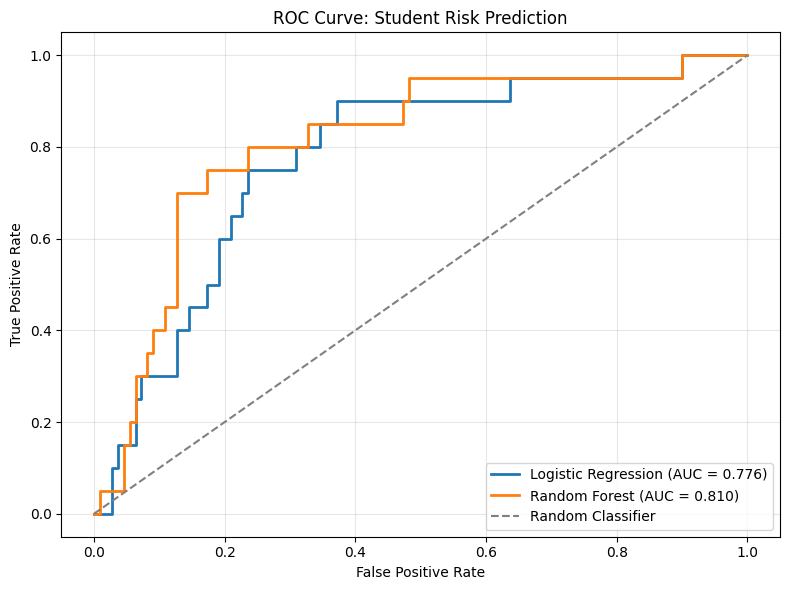

In [21]:

# Cell 21: ROC Curve Comparison

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Logistic Regression", lr_probabilities),
    ("Random Forest", rf_probabilities)
]:
    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Student Risk Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

# Cell 22: Save Cross-Validation Results

cv_results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

print("Cross-validation results saved!")


Cross-validation results saved!


In [23]:

# Cell 23: Prediction Error Analysis

error_analysis = prediction_results.copy()

error_analysis["Correct_Prediction"] = (
    error_analysis["Actual_Risk"]
    == error_analysis["Predicted_Risk"]
)

incorrect = error_analysis[
    ~error_analysis["Correct_Prediction"]
]

print("Total test students:", len(error_analysis))
print("Correct predictions:",
      error_analysis["Correct_Prediction"].sum())
print("Incorrect predictions:", len(incorrect))

print("\nINCORRECT PREDICTIONS")
display(incorrect.head(15))

# Count different types of errors
false_negatives = (
    (error_analysis["Actual_Risk"] == 1) &
    (error_analysis["Predicted_Risk"] == 0)
).sum()

false_positives = (
    (error_analysis["Actual_Risk"] == 0) &
    (error_analysis["Predicted_Risk"] == 1)
).sum()

print("\nFalse Negatives:", false_negatives)
print("False Positives:", false_positives)


Total test students: 130
Correct predictions: 100
Incorrect predictions: 30

INCORRECT PREDICTIONS


,Actual_Risk,Predicted_Risk,Risk_Probability,Actual_Category,Predicted_Category,Correct_Prediction
8,1,0,0.198321,At Risk,Not At Risk,False
10,0,1,0.512875,Not At Risk,At Risk,False
13,1,0,0.266362,At Risk,Not At Risk,False
18,0,1,0.586137,Not At Risk,At Risk,False
21,0,1,0.662813,Not At Risk,At Risk,False
23,0,1,0.674672,Not At Risk,At Risk,False
25,1,0,0.220139,At Risk,Not At Risk,False
26,0,1,0.570976,Not At Risk,At Risk,False
31,0,1,0.886327,Not At Risk,At Risk,False
33,0,1,0.664970,Not At Risk,At Risk,False



False Negatives: 8
False Positives: 22


TOP 10 IMPORTANT FEATURES


,Feature,Importance
5,num__failures,0.099832
14,cat__school_MS,0.059148
13,cat__school_GP,0.050976
12,num__absences,0.047381
8,num__goout,0.038283
4,num__studytime,0.035153
7,num__freetime,0.034408
10,num__Walc,0.033868
6,num__famrel,0.033043
2,num__Fedu,0.033000


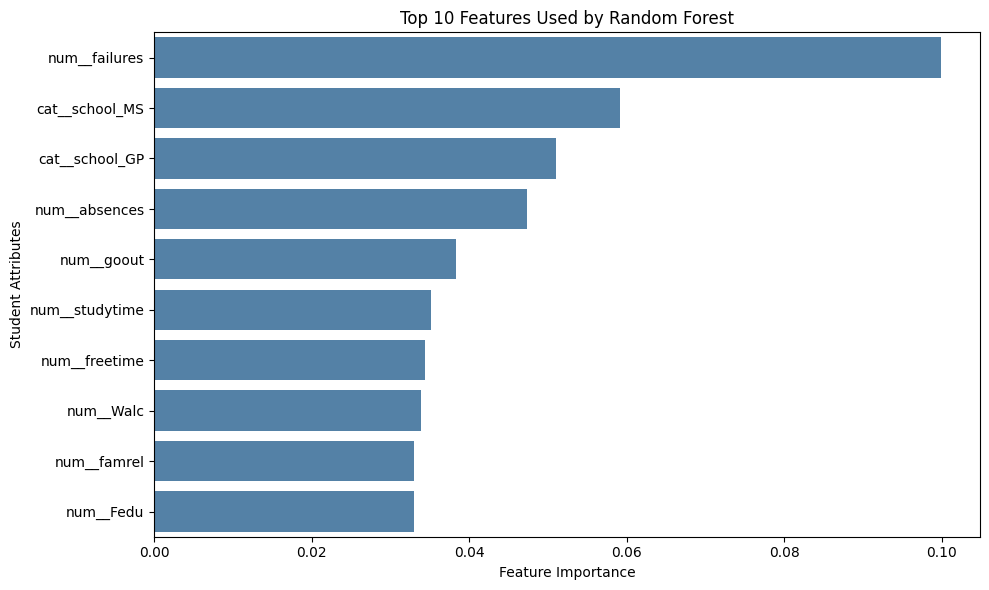


Most important feature:
num__failures


In [24]:

# Cell 24: Feature Importance Summary

top_features = feature_importance.head(10).copy()

print("TOP 10 IMPORTANT FEATURES")
display(top_features)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Features Used by Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Student Attributes")
plt.tight_layout()
plt.show()

print("\nMost important feature:")
print(top_features.iloc[0]["Feature"])


In [25]:

# Cell 25: Final Project Summary

print("=" * 55)
print("STUDENT SUCCESS PREDICTOR - PROJECT SUMMARY")
print("=" * 55)

print("\nDataset: UCI Student Performance")
print("Total students:", len(df))
print("Input features:", X.shape[1])

print("\nClassification:")
print("0 = Not At Risk")
print("1 = At Risk")

print("\nAlgorithms:")
print("1. Logistic Regression")
print("2. Random Forest")

print("\nMODEL PERFORMANCE")
display(results.round(4))

print("\nCROSS-VALIDATION PERFORMANCE")
display(cv_results_df.round(4))

print("\nSELECTED MODEL:", best_model_name)

print("\nTOP FIVE RANDOM FOREST FEATURES")
display(feature_importance.head(5))


STUDENT SUCCESS PREDICTOR - PROJECT SUMMARY

Dataset: UCI Student Performance
Total students: 649
Input features: 30

Classification:
0 = Not At Risk
1 = At Risk

Algorithms:
1. Logistic Regression
2. Random Forest

MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7692,0.3529,0.60,0.4444,0.7759
1,Random Forest,0.8385,0.3333,0.05,0.0870,0.8105



CROSS-VALIDATION PERFORMANCE


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.7534,0.3393,0.625,0.4395,0.7592
1,Random Forest,0.8459,0.4500,0.075,0.1267,0.8409



SELECTED MODEL: Logistic Regression

TOP FIVE RANDOM FOREST FEATURES


,Feature,Importance
5,num__failures,0.099832
14,cat__school_MS,0.059148
13,cat__school_GP,0.050976
12,num__absences,0.047381
8,num__goout,0.038283


In [26]:

# Cell 26: Download Project Results

from google.colab import files

files.download("model_comparison.csv")
files.download("cross_validation_results.csv")
files.download("feature_importance.csv")
files.download("student_risk_predictions.csv")
files.download("student_success_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

# Cell 27: Select best model using cross-validation

# Choose the model with the highest cross-validation F1 score
best_cv_row = cv_results_df.loc[
    cv_results_df["CV F1"].idxmax()
]

best_model_name = best_cv_row["Model"]

best_model = models[best_model_name]

print("BEST MODEL BASED ON CROSS-VALIDATION")
print("----------------------------------")
print("Model:", best_model_name)
print("CV F1 Score:", round(best_cv_row["CV F1"], 4))
print("CV Recall:", round(best_cv_row["CV Recall"], 4))
print("CV ROC-AUC:", round(best_cv_row["CV ROC-AUC"], 4))


BEST MODEL BASED ON CROSS-VALIDATION
----------------------------------
Model: Logistic Regression
CV F1 Score: 0.4395
CV Recall: 0.625
CV ROC-AUC: 0.7592


In [28]:

# Cell 28: Final test evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

final_predictions = best_model.predict(X_test)
final_probabilities = best_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(
        y_test, final_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, final_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, final_probabilities
    )
}

print("FINAL SELECTED MODEL:", best_model_name)
print("----------------------------------")

for metric, score in final_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, final_predictions))


FINAL SELECTED MODEL: Logistic Regression
----------------------------------
Accuracy: 0.7692
Precision: 0.3529
Recall: 0.6000
F1 Score: 0.4444
ROC-AUC: 0.7759

CONFUSION MATRIX
[[88 22]
 [ 8 12]]


In [29]:

# Cell 29: Save final model and metrics

import joblib
import pandas as pd

joblib.dump(
    best_model,
    "student_success_final_model.pkl"
)

final_results_df = pd.DataFrame(
    [final_metrics]
)

final_results_df.insert(
    0, "Selected_Model", best_model_name
)

final_results_df.to_csv(
    "final_model_results.csv",
    index=False
)

print("Final model and results saved successfully!")
display(final_results_df)


Final model and results saved successfully!


,Selected_Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.769231,0.352941,0.6,0.444444,0.775909


Class counts: {0: 439, 1: 80}
Class proportions: {0: 0.846, 1: 0.154}


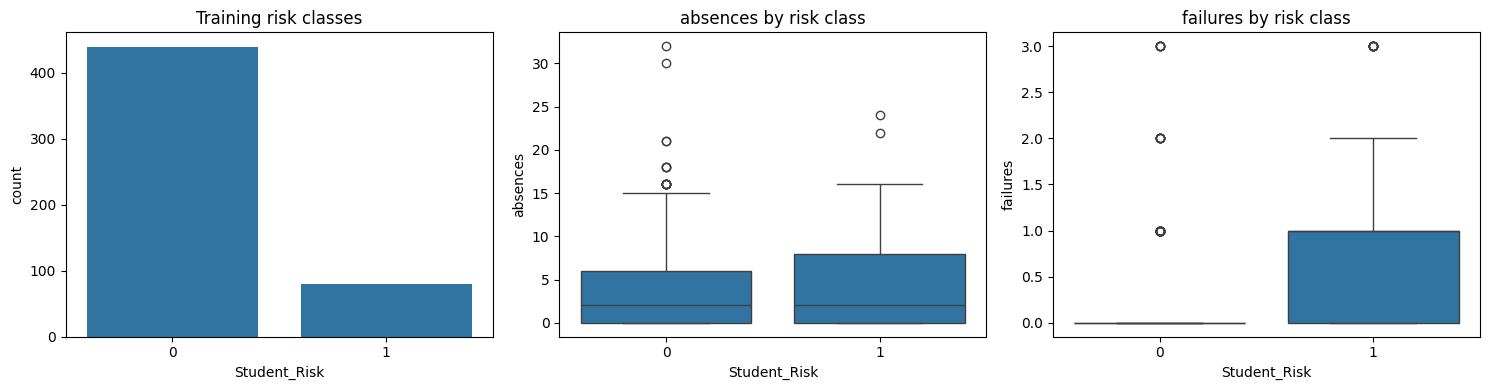


Risk rate by studytime:


,count,mean
studytime,,
1,171,0.257
2,250,0.124
3,72,0.056
4,26,0.038



Risk rate by failures:


,count,mean
failures,,
0,435,0.087
1,56,0.446
2,14,0.571
3,14,0.643



Risk rate by higher:


,count,mean
higher,,
no,56,0.464
yes,463,0.117


In [30]:
# Extension 1 — EDA and class balance
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
print('Class counts:', y_train.value_counts().to_dict())
print('Class proportions:', y_train.value_counts(normalize=True).round(3).to_dict())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x=y_train, ax=axes[0]); axes[0].set_title('Training risk classes')
for ax, col in zip(axes[1:], ['absences','failures']):
    sns.boxplot(x=y_train, y=X_train[col], ax=ax)
    ax.set_title(f'{col} by risk class')
plt.tight_layout(); plt.show()
for col in ['studytime','failures','higher']:
    print(f'\nRisk rate by {col}:')
    display(pd.DataFrame({col:X_train[col], 'risk':y_train}).groupby(col)['risk'].agg(['count','mean']).round(3))

In [31]:
# Extension 2 — SVM, Gradient Boosting, AdaBoost, optional XGBoost
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
advanced_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
advanced_models = {
    'Logistic Regression': clone(lr_model),
    'Random Forest': clone(rf_model),
    'SVM': Pipeline([('preprocessor',clone(preprocessor)),('classifier',SVC(probability=True, class_weight='balanced',random_state=42))]),
    'Gradient Boosting': Pipeline([('preprocessor',clone(preprocessor)),('classifier',GradientBoostingClassifier(random_state=42))]),
    'AdaBoost': Pipeline([('preprocessor',clone(preprocessor)),('classifier',AdaBoostClassifier(random_state=42))]),
}
try:
    from xgboost import XGBClassifier
    advanced_models['XGBoost'] = Pipeline([('preprocessor',clone(preprocessor)),('classifier',XGBClassifier(n_estimators=150, max_depth=3, learning_rate=.05, eval_metric='logloss', random_state=42, n_jobs=2))])
    print('XGBoost available.')
except ImportError:
    print('XGBoost unavailable: optional model skipped. Install with %pip install xgboost if desired.')
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
advanced_cv_rows=[]
for name, model in advanced_models.items():
    scores=cross_validate(model,X_train,y_train,cv=advanced_cv,scoring=scoring,n_jobs=1,error_score='raise')
    advanced_cv_rows.append({'Model':name,**{'CV '+k:scores['test_'+k].mean() for k in scoring}})
advanced_cv_df=pd.DataFrame(advanced_cv_rows).sort_values('CV f1',ascending=False)
display(advanced_cv_df.round(3))

XGBoost available.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc
2,SVM,0.811,0.405,0.488,0.440,0.793
0,Logistic Regression,0.753,0.339,0.625,0.440,0.759
5,XGBoost,0.857,0.593,0.312,0.398,0.807
3,Gradient Boosting,0.844,0.494,0.312,0.376,0.794
4,AdaBoost,0.844,0.532,0.300,0.372,0.796
1,Random Forest,0.846,0.450,0.075,0.127,0.841


In [32]:
# Extension 3 — Hyperparameter tuning (train folds only)
from sklearn.model_selection import RandomizedSearchCV
search_spaces={
 'Logistic Regression': {'classifier__C':[.01,.1,1,10]},
 'Random Forest': {'classifier__n_estimators':[100,200], 'classifier__max_depth':[5,10,None], 'classifier__min_samples_leaf':[1,3]},
 'SVM': {'classifier__C':[.1,1,10], 'classifier__gamma':['scale',.01]},
 'Gradient Boosting': {'classifier__n_estimators':[80,150], 'classifier__learning_rate':[.03,.1], 'classifier__max_depth':[2,3]},
 'AdaBoost': {'classifier__n_estimators':[50,100,150], 'classifier__learning_rate':[.05,.5,1]},
 'XGBoost': {'classifier__n_estimators':[100,200], 'classifier__max_depth':[2,4], 'classifier__learning_rate':[.03,.1]}
}
tuned_models={}; tuning_rows=[]
for name, model in advanced_models.items():
    search=RandomizedSearchCV(clone(model),search_spaces[name],n_iter=5,scoring='f1',cv=advanced_cv,random_state=42,n_jobs=1,refit=True)
    search.fit(X_train,y_train)
    tuned_models[name]=search.best_estimator_
    tuning_rows.append({'Model':name,'Tuned CV F1':search.best_score_,'Best parameters':str(search.best_params_)})
tuning_df=pd.DataFrame(tuning_rows).sort_values('Tuned CV F1',ascending=False)
display(tuning_df)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=5. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


,Model,Tuned CV F1,Best parameters
0,Logistic Regression,0.508242,{'classifier__C': 0.01}
2,SVM,0.495970,"{'classifier__gamma': 'scale', 'classifier__C'..."
1,Random Forest,0.442144,"{'classifier__n_estimators': 100, 'classifier_..."
5,XGBoost,0.392429,"{'classifier__n_estimators': 200, 'classifier_..."
4,AdaBoost,0.372521,"{'classifier__n_estimators': 100, 'classifier_..."
3,Gradient Boosting,0.362403,"{'classifier__n_estimators': 150, 'classifier_..."


In [33]:
# Extension 4 — Imbalance strategy: compare class weights and SMOTE if available
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score
imbalance_models={
 'LR unweighted':Pipeline([('preprocessor',clone(preprocessor)),('classifier',LogisticRegression(max_iter=2000,random_state=42))]),
 'LR class weighted':Pipeline([('preprocessor',clone(preprocessor)),('classifier',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42))])
}
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    # One-hot encoding precedes SMOTE here; use cautiously with categorical features.
    imbalance_models['LR SMOTE (encoded)']=ImbPipeline([('preprocessor',clone(preprocessor)),('smote',SMOTE(random_state=42,k_neighbors=3)),('classifier',LogisticRegression(max_iter=2000,random_state=42))])
except ImportError:
    print('imbalanced-learn unavailable; SMOTE skipped. Optional: %pip install imbalanced-learn')
imbalance_rows=[]
for name,model in imbalance_models.items():
    try:
        scores=cross_validate(model,X_train,y_train,cv=advanced_cv,scoring={'f1':'f1','recall':'recall','precision':'precision'},error_score='raise')
        imbalance_rows.append({'Strategy':name,**{k:scores['test_'+k].mean() for k in ['f1','recall','precision']}})
    except Exception as exc:
        print(name,'skipped:',str(exc)[:180])
imbalance_df=pd.DataFrame(imbalance_rows)
display(imbalance_df.round(3))

,Strategy,f1,recall,precision
0,LR unweighted,0.370,0.300,0.503
1,LR class weighted,0.440,0.625,0.339
2,LR SMOTE (encoded),0.411,0.550,0.329


In [34]:
# Extension 5 — SelectKBest and PCA: nested preprocessing inside CV
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
feature_models={
 'No reduction': Pipeline([('preprocessor',clone(preprocessor)),('classifier',LogisticRegression(max_iter=2000,class_weight='balanced'))]),
 'SelectKBest (20)':Pipeline([('preprocessor',clone(preprocessor)),('select',SelectKBest(f_classif,k=20)),('classifier',LogisticRegression(max_iter=2000,class_weight='balanced'))]),
 'PCA (95% variance)':Pipeline([('preprocessor',clone(preprocessor)),('pca',PCA(n_components=.95)),('classifier',LogisticRegression(max_iter=2000,class_weight='balanced'))])
}
feature_rows=[]
for name,model in feature_models.items():
    scores=cross_validate(model,X_train,y_train,cv=advanced_cv,scoring={'f1':'f1','roc_auc':'roc_auc'},error_score='raise')
    feature_rows.append({'Method':name,'CV F1':scores['test_f1'].mean(),'CV ROC-AUC':scores['test_roc_auc'].mean()})
feature_df=pd.DataFrame(feature_rows).sort_values('CV F1',ascending=False)
display(feature_df.round(3))
print('LDA is supervised; it is optional here because binary LDA yields at most one component.')

,Method,CV F1,CV ROC-AUC
1,SelectKBest (20),0.505,0.798
2,PCA (95% variance),0.455,0.780
0,No reduction,0.440,0.759


LDA is supervised; it is optional here because binary LDA yields at most one component.


Model selected using training CV: Logistic Regression
Threshold selected using training out-of-fold F1: 0.511
Threshold 0.300: F1=0.337, recall=0.938, precision=0.205
Threshold 0.500: F1=0.507, recall=0.713, precision=0.393
Threshold 0.700: F1=0.387, recall=0.300, precision=0.545
Threshold 0.511: F1=0.511, recall=0.700, precision=0.403


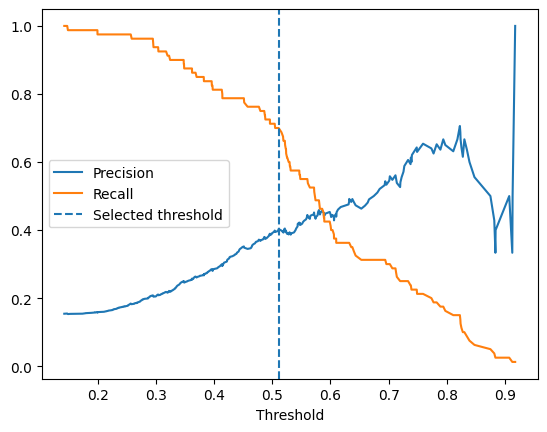

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'Medu', 'Fedu',
                                                   'traveltime', 'studytime',
                                                   'failures', 'famrel',
                                                   'freetime', 'goout', 'Dalc',
                                                   'Walc', 'health',
                                                   'absences']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['school', 'sex', 'address',
                                                   'famsize', 'Pstatus', 'Mjob',
                                                   'Fjob', 'reason', 'guardian',
                                                   'schoolsup', 'famsup',
                                                   'paid', 'activities',
                                                   'nursery', 'higher',
                                                   'internet', 'romantic'])])),
                ('classifier',
                 LogisticRegression(C=0.01, class_weight='balanced',
                                    max_iter=2000, random_state=42))])

In [35]:
# Extension 6 — Select tuned model by training CV, get out-of-fold probabilities
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix, classification_report
advanced_best_name=tuning_df.iloc[0]['Model']
advanced_best_model=clone(tuned_models[advanced_best_name])
oof_probs=cross_val_predict(advanced_best_model,X_train,y_train,cv=advanced_cv,method='predict_proba',n_jobs=1)[:,1]
prec,rec,thresholds=precision_recall_curve(y_train,oof_probs)
f1_values=2*prec[:-1]*rec[:-1]/np.maximum(prec[:-1]+rec[:-1],1e-12)
idx=int(np.argmax(f1_values))
chosen_threshold=float(thresholds[idx])
print('Model selected using training CV:',advanced_best_name)
print('Threshold selected using training out-of-fold F1:',round(chosen_threshold,3))
for threshold in [.3,.5,.7,chosen_threshold]:
    pred=(oof_probs>=threshold).astype(int)
    print(f'Threshold {threshold:.3f}: F1={f1_score(y_train,pred,zero_division=0):.3f}, recall={recall_score(y_train,pred,zero_division=0):.3f}, precision={precision_score(y_train,pred,zero_division=0):.3f}')
plt.plot(thresholds,prec[:-1],label='Precision');plt.plot(thresholds,rec[:-1],label='Recall')
plt.axvline(chosen_threshold,ls='--',label='Selected threshold');plt.xlabel('Threshold');plt.legend();plt.show()
advanced_best_model.fit(X_train,y_train)

In [36]:
# Extension 7 — SHAP global and local explanations (optional dependency)
try:
    import shap
    # Model-agnostic SHAP on raw input columns (works for any selected pipeline).
    # Small background/explanation sets keep this manageable in Colab.
    background=X_train.sample(n=min(30,len(X_train)),random_state=42)
    examples=X_train.sample(n=min(8,len(X_train)),random_state=7)
    predictor=lambda z: advanced_best_model.predict_proba(pd.DataFrame(z,columns=X_train.columns))[:,1]
    explainer=shap.Explainer(predictor,background,algorithm='permutation')
    shap_values=explainer(examples,max_evals=2*X_train.shape[1]+1)
    shap.plots.bar(shap_values,max_display=12)
    shap.plots.waterfall(shap_values[0],max_display=12)
except ImportError:
    print('SHAP not installed. In Colab run %pip install shap, then rerun this cell.')
except Exception as exc:
    print('SHAP could not run in this environment:',type(exc).__name__,str(exc)[:250])

SHAP could not run in this environment: TypeError unsupported operand type(s) for -: 'str' and 'str'


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.511,0.792,0.36,0.45,0.4,0.79


              precision    recall  f1-score   support

           0       0.90      0.85      0.87       110
           1       0.36      0.45      0.40        20

    accuracy                           0.79       130
   macro avg       0.63      0.65      0.64       130
weighted avg       0.81      0.79      0.80       130



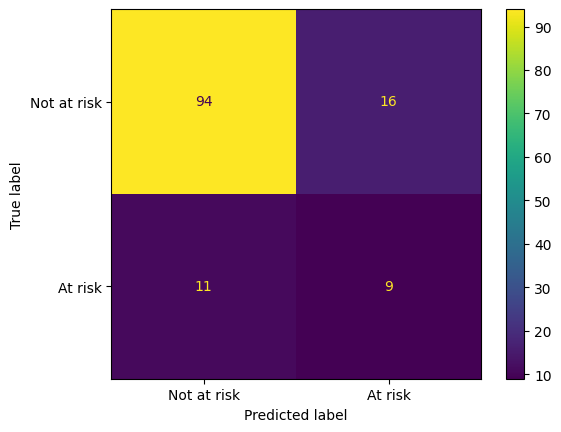

Error_Type
Correct           103
False Positive     16
False Negative     11
Name: count, dtype: int64


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,Actual_Risk,Predicted_Risk,Risk_Probability,Error_Type
168,GP,M,15,R,GT3,T,2,3,at_home,services,...,4,4,1,1,1,0,1,0,0.330243,False Negative
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,5,6,1,0,0.428090,False Negative
627,MS,M,18,R,LE3,T,1,2,at_home,services,...,3,3,2,3,3,3,0,1,0.612328,False Positive
178,GP,M,17,R,LE3,T,1,1,other,services,...,3,5,1,5,5,0,1,0,0.506451,False Negative
173,GP,M,16,U,LE3,T,1,2,health,services,...,4,5,3,5,5,0,0,1,0.797224,False Positive
471,MS,F,16,R,GT3,T,2,2,at_home,other,...,4,4,2,3,5,2,0,1,0.654054,False Positive
559,MS,M,18,R,GT3,T,1,0,at_home,at_home,...,3,2,1,1,4,0,0,1,0.729539,False Positive
574,MS,M,20,R,GT3,T,1,1,other,other,...,4,3,2,4,4,12,0,1,0.855892,False Positive
481,MS,F,17,R,GT3,T,2,1,at_home,other,...,5,3,1,1,3,2,0,1,0.645828,False Positive
531,MS,M,17,U,GT3,T,1,1,at_home,services,...,1,3,3,3,1,0,0,1,0.520841,False Positive


In [37]:
# Extension 8 — One-time held-out test evaluation and error analysis
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,ConfusionMatrixDisplay
advanced_test_probs=advanced_best_model.predict_proba(X_test)[:,1]
advanced_test_preds=(advanced_test_probs>=chosen_threshold).astype(int)
advanced_test_metrics={'Model':advanced_best_name,'Threshold':chosen_threshold,'Accuracy':accuracy_score(y_test,advanced_test_preds),'Precision':precision_score(y_test,advanced_test_preds,zero_division=0),'Recall':recall_score(y_test,advanced_test_preds,zero_division=0),'F1':f1_score(y_test,advanced_test_preds,zero_division=0),'ROC-AUC':roc_auc_score(y_test,advanced_test_probs)}
display(pd.DataFrame([advanced_test_metrics]).round(3))
print(classification_report(y_test,advanced_test_preds,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,advanced_test_preds,display_labels=['Not at risk','At risk']);plt.show()
advanced_errors=X_test.copy();advanced_errors['Actual_Risk']=y_test.to_numpy();advanced_errors['Predicted_Risk']=advanced_test_preds;advanced_errors['Risk_Probability']=advanced_test_probs
advanced_errors['Error_Type']=np.select([(advanced_errors.Actual_Risk==1)&(advanced_errors.Predicted_Risk==0),(advanced_errors.Actual_Risk==0)&(advanced_errors.Predicted_Risk==1)],['False Negative','False Positive'],default='Correct')
print(advanced_errors['Error_Type'].value_counts());display(advanced_errors.loc[advanced_errors.Error_Type!='Correct'].head(15))

In [38]:
# Extension 9 — Cross-dataset validation: mathematics ↔ Portuguese
# Upload student-mat.csv in Colab first. If absent, this experiment is skipped.
from pathlib import Path
from sklearn.metrics import f1_score,recall_score,roc_auc_score
if Path('student-mat.csv').exists() and Path('student-por.csv').exists():
    mat=pd.read_csv('student-mat.csv',sep=';');por=pd.read_csv('student-por.csv',sep=';')
    common=sorted(set(mat.columns).intersection(por.columns)-{'G1','G2','G3','Student_Risk','Study_Time_Category'})
    transfer_rows=[]
    for source_name,source,target_name,target in [('Math',mat,'Portuguese',por),('Portuguese',por,'Math',mat)]:
        source_y=(source.G3<10).astype(int);target_y=(target.G3<10).astype(int)
        # Rebuild preprocessing using shared columns and fit only on source data.
        from sklearn.compose import make_column_selector
        source_num=source[common].select_dtypes(include=np.number).columns.tolist()
        source_cat=[c for c in common if c not in source_num]
        transfer_pre=ColumnTransformer([('num',StandardScaler(),source_num),('cat',OneHotEncoder(handle_unknown='ignore'),source_cat)])
        transfer_model=Pipeline([('preprocessor',transfer_pre),('classifier',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42))])
        transfer_model.fit(source[common],source_y)
        probs=transfer_model.predict_proba(target[common])[:,1];pred=(probs>=.5).astype(int)
        transfer_rows.append({'Train':source_name,'Test':target_name,'F1':f1_score(target_y,pred,zero_division=0),'Recall':recall_score(target_y,pred,zero_division=0),'ROC-AUC':roc_auc_score(target_y,probs)})
    transfer_df=pd.DataFrame(transfer_rows);display(transfer_df.round(3))
    print('Caution: math and Portuguese files may include overlapping students; cross-subject transfer is not fully independent external validation.')
else:
    transfer_df=pd.DataFrame()
    print('Upload student-mat.csv alongside student-por.csv, then rerun this cell.')

,Train,Test,F1,Recall,ROC-AUC
0,Math,Portuguese,0.344,0.670,0.687
1,Portuguese,Math,0.460,0.377,0.629


Caution: math and Portuguese files may include overlapping students; cross-subject transfer is not fully independent external validation.


In [39]:
# Extension 10 — Save reproducible advanced results and fitted pipeline
import joblib
advanced_cv_df.to_csv('advanced_model_cv_comparison.csv',index=False)
tuning_df.to_csv('advanced_hyperparameter_tuning.csv',index=False)
imbalance_df.to_csv('advanced_imbalance_comparison.csv',index=False)
feature_df.to_csv('advanced_feature_selection_comparison.csv',index=False)
pd.DataFrame([advanced_test_metrics]).to_csv('advanced_final_test_metrics.csv',index=False)
advanced_errors.to_csv('advanced_test_error_analysis.csv',index=False)
if not transfer_df.empty: transfer_df.to_csv('advanced_cross_dataset_validation.csv',index=False)
joblib.dump({'model':advanced_best_model,'threshold':chosen_threshold,'feature_columns':X_train.columns.tolist()},'advanced_student_risk_model.joblib')
print('Saved advanced experiment CSVs and model. Selected model:',advanced_best_name)
print('Final test F1:',round(advanced_test_metrics['F1'],3),'Recall:',round(advanced_test_metrics['Recall'],3))

Saved advanced experiment CSVs and model. Selected model: Logistic Regression
Final test F1: 0.4 Recall: 0.45
